In [ ]:
import numpy as np


In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [4]:
import seaborn as sns

In [5]:
df = pd.read_csv("~/Downloads/HousingData.csv")

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [14]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [12]:
X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

print("Features shape:", X.shape)

print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']


/var/folders/vr/1lp3_ky11vx3ptjnrz6jy_1m0000gn/T/ipykernel_4767/1329431653.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [18]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [19]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [20]:
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [21]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (16512, 13)
Processed testing shape: (4128, 13)


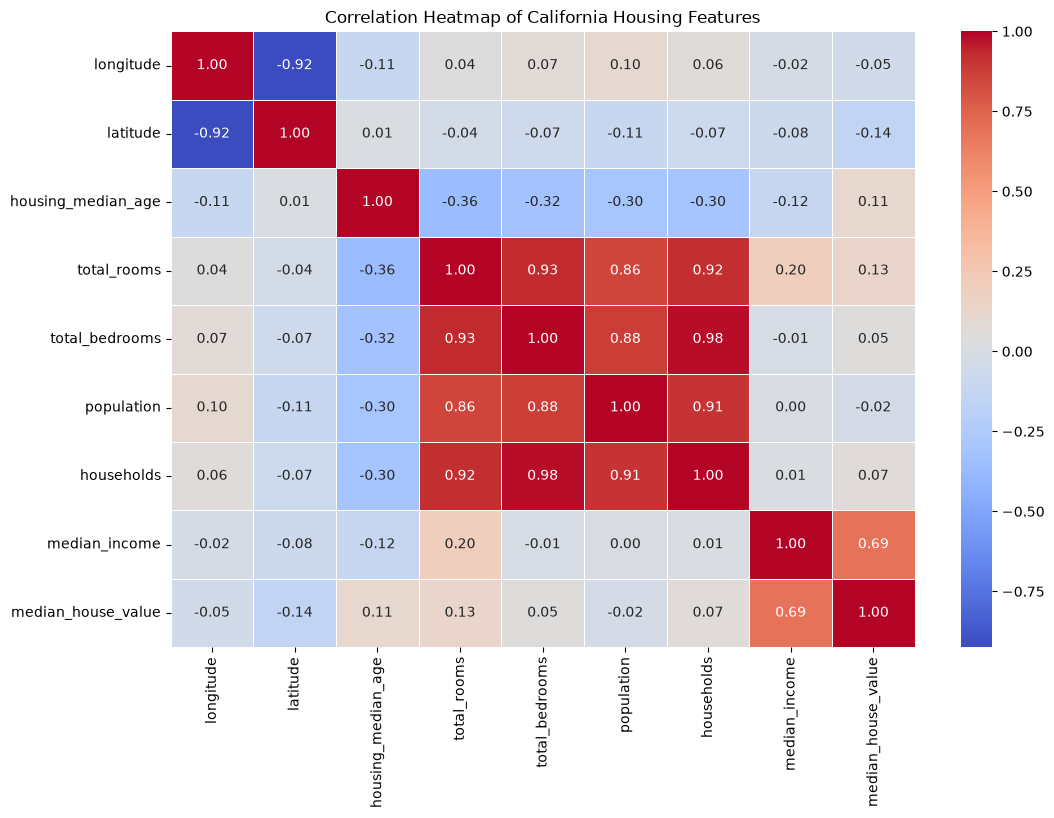

In [22]:
# Select numerical columns only
numerical_df = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numerical_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of California Housing Features")
plt.show()

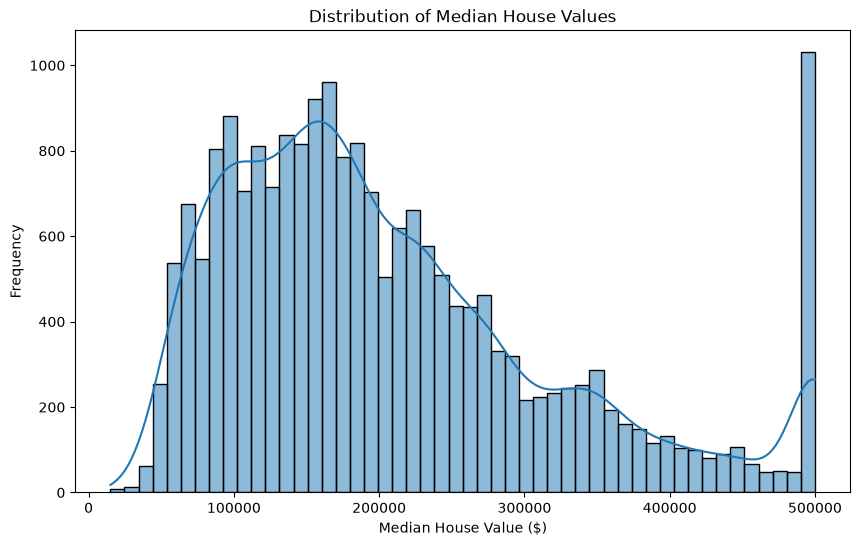

In [23]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")

plt.show()

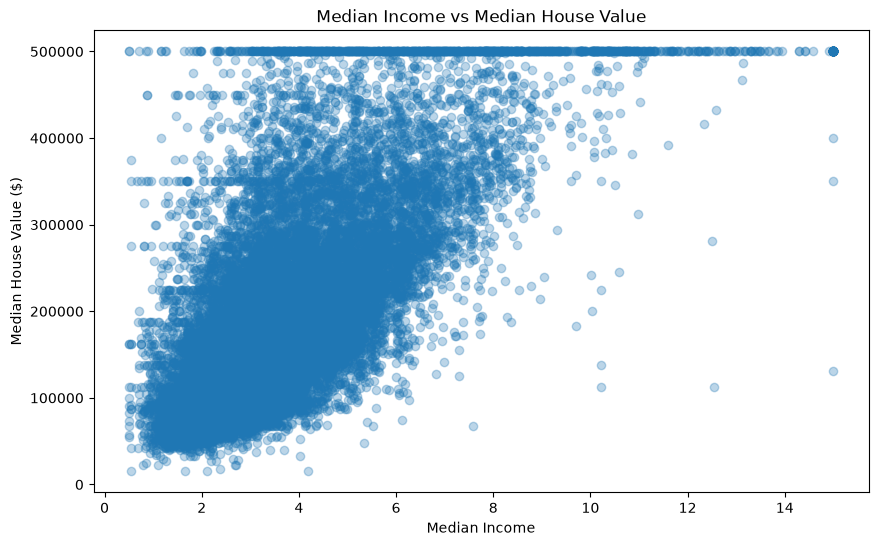

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")

plt.show()

In [25]:
# Create copies of the original training and testing features
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Create interaction features
for data in [X_train_fe, X_test_fe]:
    data["income_house_age"] = (
        data["median_income"] * data["housing_median_age"]
    )

    data["income_rooms"] = (
        data["median_income"] * data["total_rooms"]
    )

print("Training features after engineering:", X_train_fe.shape)
print("Testing features after engineering:", X_test_fe.shape)

Training features after engineering: (16512, 11)
Testing features after engineering: (4128, 11)


In [26]:
# Identify numerical and categorical features after feature engineering
numerical_features = X_train_fe.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_fe.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'income_house_age', 'income_rooms']
Categorical features: ['ocean_proximity']


/var/folders/vr/1lp3_ky11vx3ptjnrz6jy_1m0000gn/T/ipykernel_4767/2375443003.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train_fe.select_dtypes(


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the transformations
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [28]:
from sklearn.linear_model import LinearRegression

# Create the OLS model pipeline
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
ols_model.fit(X_train_fe, y_train)

print("OLS model trained successfully!")

OLS model trained successfully!


In [29]:
# Predict house values using the test features
y_pred_ols = ols_model.predict(X_test_fe)

# Display a few predictions
print("Actual values:", y_test.iloc[:5].values)
print("Predicted values:", y_pred_ols[:5])

Actual values: [ 47700.  45800. 500001. 218600. 278000.]
Predicted values: [ 64052.01608172 115503.68821813 234118.04968606 261083.78953006
 259659.54798932]


In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Calculate evaluation metrics
rmse_ols = np.sqrt(mean_squared_error(y_test, y_pred_ols))
mae_ols = mean_absolute_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print("OLS Regression Results")
print("----------------------")
print("RMSE:", rmse_ols)
print("MAE:", mae_ols)
print("R² Score:", r2_ols)

OLS Regression Results
----------------------
RMSE: 70122.6652697144
MAE: 50095.31062688112
R² Score: 0.6247592723968305


In [31]:
results = {
    "OLS": {
        "RMSE": rmse_ols,
        "MAE": mae_ols,
        "R2": r2_ols
    }
}

print(results)

{'OLS': {'RMSE': np.float64(70122.6652697144), 'MAE': 50095.31062688112, 'R2': 0.6247592723968305}}


In [32]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

In [33]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

In [34]:
param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

In [35]:
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

ridge_grid.fit(X_train_fe, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how t

In [36]:
print("Best alpha:", ridge_grid.best_params_["regressor__alpha"])

print("Best cross-validation RMSE:", -ridge_grid.best_score_)

Best alpha: 1
Best cross-validation RMSE: 68179.8768840571


In [37]:
y_pred_ridge = ridge_grid.best_estimator_.predict(X_test_fe)

In [38]:
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("-------------------------")
print("RMSE:", rmse_ridge)
print("MAE:", mae_ridge)
print("R² Score:", r2_ridge)

Ridge Regression Results
-------------------------
RMSE: 70125.32052646896
MAE: 50100.1723773086
R² Score: 0.6247308542145851


In [39]:
results["Ridge"] = {
    "RMSE": rmse_ridge,
    "MAE": mae_ridge,
    "R2": r2_ridge
}

print(results)

{'OLS': {'RMSE': np.float64(70122.6652697144), 'MAE': 50095.31062688112, 'R2': 0.6247592723968305}, 'Ridge': {'RMSE': np.float64(70125.32052646896), 'MAE': 50100.1723773086, 'R2': 0.6247308542145851}}


In [40]:
from sklearn.linear_model import Lasso

In [41]:
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

In [42]:
lasso_param_grid = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

In [43]:
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

lasso_grid.fit(X_train_fe, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.947786e+12, tolerance: 1.779e+10
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.905359e+12, tolerance: 1.757e+10
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number o

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=20000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how t

In [44]:
print("Best alpha:", lasso_grid.best_params_["regressor__alpha"])

print("Best cross-validation RMSE:", -lasso_grid.best_score_)

Best alpha: 0.1
Best cross-validation RMSE: 68180.67862305463


In [45]:
y_pred_lasso = lasso_grid.best_estimator_.predict(X_test_fe)

In [46]:
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Results")
print("-------------------------")
print("RMSE:", rmse_lasso)
print("MAE:", mae_lasso)
print("R² Score:", r2_lasso)

Lasso Regression Results
-------------------------
RMSE: 70122.67285754111
MAE: 50095.39327999536
R² Score: 0.6247591911888002


In [47]:
results["Lasso"] = {
    "RMSE": rmse_lasso,
    "MAE": mae_lasso,
    "R2": r2_lasso
}

print(results)

{'OLS': {'RMSE': np.float64(70122.6652697144), 'MAE': 50095.31062688112, 'R2': 0.6247592723968305}, 'Ridge': {'RMSE': np.float64(70125.32052646896), 'MAE': 50100.1723773086, 'R2': 0.6247308542145851}, 'Lasso': {'RMSE': np.float64(70122.67285754111), 'MAE': 50095.39327999536, 'R2': 0.6247591911888002}}


In [48]:
results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(by="RMSE")

print(results_df)

               RMSE           MAE        R2
OLS    70122.665270  50095.310627  0.624759
Lasso  70122.672858  50095.393280  0.624759
Ridge  70125.320526  50100.172377  0.624731


In [49]:
# Obtain the fitted Lasso regression model
lasso_model = lasso_grid.best_estimator_.named_steps["regressor"]

# Get the feature names after preprocessing
feature_names = (
    lasso_grid.best_estimator_
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Display the coefficients
lasso_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_model.coef_
})

lasso_coefficients["Absolute_Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients = lasso_coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(lasso_coefficients)

                                    Feature    Coefficient  \
12      categorical__ocean_proximity_ISLAND  137312.650994   
4                 numerical__total_bedrooms   56923.710122   
7                  numerical__median_income   56507.014175   
1                       numerical__latitude  -54558.391735   
0                      numerical__longitude  -54294.576779   
3                    numerical__total_rooms  -46184.895576   
5                     numerical__population  -41409.608908   
11      categorical__ocean_proximity_INLAND  -35078.850426   
9                   numerical__income_rooms   26746.000571   
6                     numerical__households   15189.461367   
8               numerical__income_house_age   14926.411624   
14  categorical__ocean_proximity_NEAR OCEAN    5964.716801   
2             numerical__housing_median_age    3507.765749   
10   categorical__ocean_proximity_<1H OCEAN    2713.548156   
13    categorical__ocean_proximity_NEAR BAY   -2300.223083   

    Abs

In [50]:
print(
    "Number of zero coefficients:",
    np.sum(lasso_model.coef_ == 0)
)

print(
    "Total number of coefficients:",
    len(lasso_model.coef_)
)

Number of zero coefficients: 0
Total number of coefficients: 15


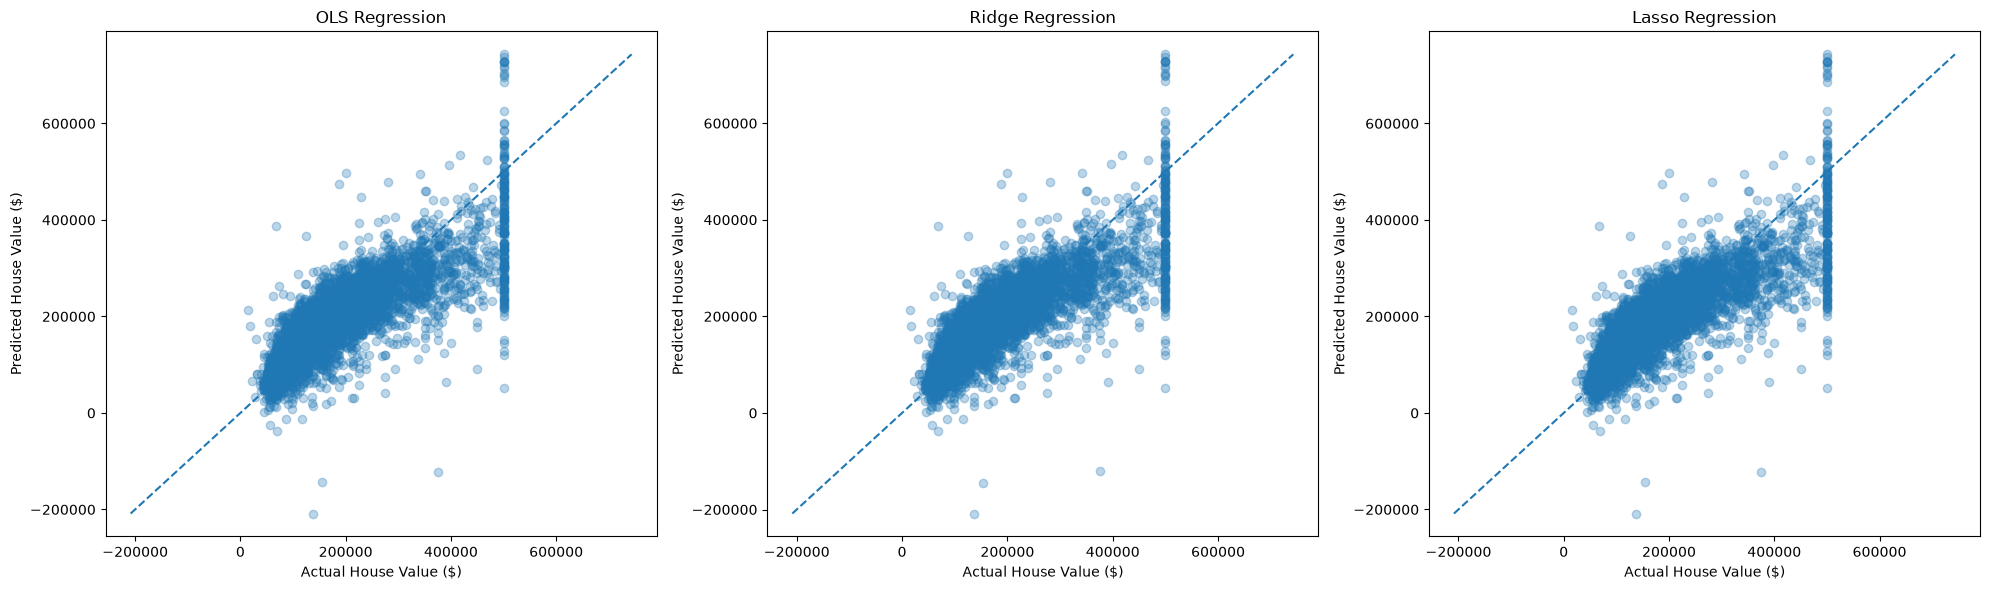

In [51]:
# Actual vs Predicted plots for all three models

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

predictions = {
    "OLS Regression": y_pred_ols,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso
}

for ax, (model_name, predictions_values) in zip(axes, predictions.items()):

    ax.scatter(y_test, predictions_values, alpha=0.3)

    # Reference line representing perfect predictions
    min_value = min(y_test.min(), predictions_values.min())
    max_value = max(y_test.max(), predictions_values.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

plt.tight_layout()
plt.show()

In [52]:
# Calculate residuals
residuals_ols = y_test - y_pred_ols
residuals_ridge = y_test - y_pred_ridge
residuals_lasso = y_test - y_pred_lasso

print("OLS residuals calculated:", len(residuals_ols))
print("Ridge residuals calculated:", len(residuals_ridge))
print("Lasso residuals calculated:", len(residuals_lasso))

OLS residuals calculated: 4128
Ridge residuals calculated: 4128
Lasso residuals calculated: 4128


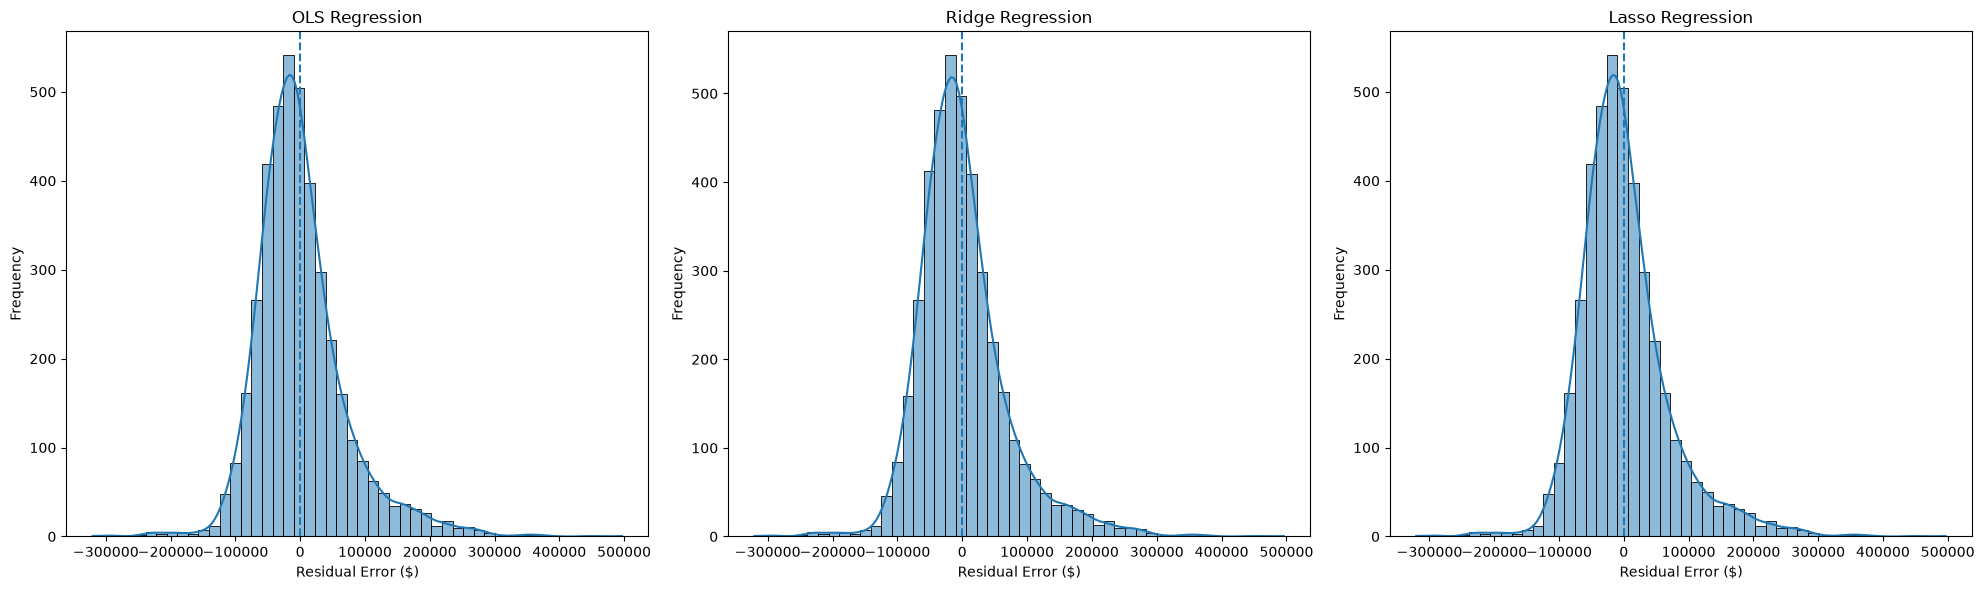

In [53]:
# Residual distribution plots

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

residual_data = {
    "OLS Regression": residuals_ols,
    "Ridge Regression": residuals_ridge,
    "Lasso Regression": residuals_lasso
}

for ax, (model_name, residuals) in zip(axes, residual_data.items()):

    sns.histplot(
        residuals,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.axvline(0, linestyle="--")

    ax.set_title(model_name)
    ax.set_xlabel("Residual Error ($)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [54]:
# Display the model comparison table

results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(by="RMSE")

results_df

,RMSE,MAE,R2
OLS,70122.665270,50095.310627,0.624759
Lasso,70122.672858,50095.393280,0.624759
Ridge,70125.320526,50100.172377,0.624731


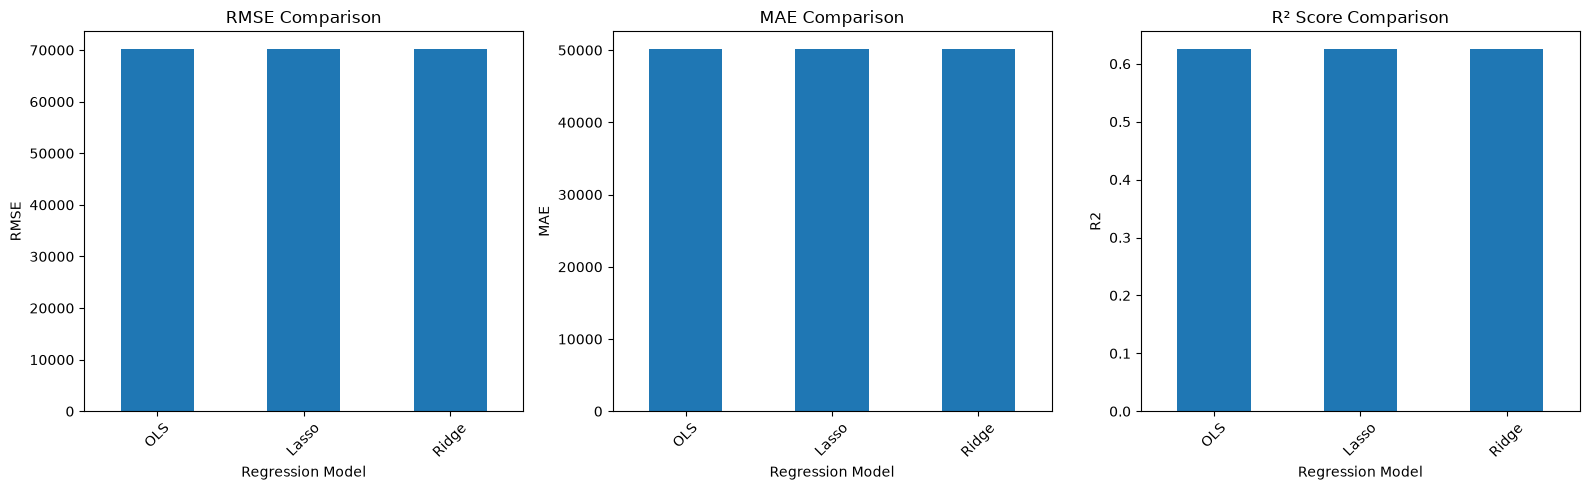

In [55]:
# Compare model performance

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["RMSE", "MAE", "R2"]
titles = [
    "RMSE Comparison",
    "MAE Comparison",
    "R² Score Comparison"
]

for i, metric in enumerate(metrics):
    results_df[metric].plot(
        kind="bar",
        ax=axes[i]
    )

    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Regression Model")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [56]:
print("Ridge Best Alpha:",
      ridge_grid.best_params_["regressor__alpha"])

print("Lasso Best Alpha:",
      lasso_grid.best_params_["regressor__alpha"])

print("Ridge Best CV RMSE:",
      -ridge_grid.best_score_)

print("Lasso Best CV RMSE:",
      -lasso_grid.best_score_)

Ridge Best Alpha: 1
Lasso Best Alpha: 0.1
Ridge Best CV RMSE: 68179.8768840571
Lasso Best CV RMSE: 68180.67862305463


In [57]:
results_df = pd.DataFrame(results).T

results_df.index.name = "Model"

results_df = results_df.sort_values("RMSE")

print(results_df.round(4))

             RMSE         MAE      R2
Model                                
OLS    70122.6653  50095.3106  0.6248
Lasso  70122.6729  50095.3933  0.6248
Ridge  70125.3205  50100.1724  0.6247
